In [1]:

# REDES NEURONALES III
# Notebook 3: Regularización

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split

# Fijar semillas para reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Notebook 3 preparado correctamente.")


TensorFlow: 2.21.0
Notebook 3 preparado correctamente.


In [2]:

# Cargar MNIST
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# Separar Train y Dev
x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Normalizar imágenes entre 0 y 1
x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Verificar dimensiones
print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [17]:

from sklearn.model_selection import train_test_split

# Crear una muestra estratificada de 12.000 imágenes
x_train_reg, _, y_train_reg, _ = train_test_split(
    x_train,
    y_train,
    train_size=12000,
    random_state=SEED,
    stratify=y_train
)

print("Muestra para experimento de regularización:")
print("Imágenes:", x_train_reg.shape)
print("Etiquetas:", y_train_reg.shape)

print("\nDistribución de clases:")
print(np.bincount(y_train_reg))


Muestra para experimento de regularización:
Imágenes: (12000, 28, 28)
Etiquetas: (12000,)

Distribución de clases:
[1184 1349 1192 1226 1168 1084 1184 1253 1170 1190]


In [4]:

# Función para crear modelos con diferentes regularizaciones
def crear_modelo_regularizacion(tipo="baseline"):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten()
    ])

    if tipo == "dropout":
        modelo.add(layers.Dense(128, activation="relu"))
        modelo.add(layers.Dropout(0.3))

    elif tipo == "l2":
        modelo.add(layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ))

    elif tipo == "dropout_l2":
        modelo.add(layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ))
        modelo.add(layers.Dropout(0.3))

    else:
        modelo.add(layers.Dense(128, activation="relu"))

    modelo.add(layers.Dense(10, activation="softmax"))

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

print("Función de regularización creada correctamente.")


Función de regularización creada correctamente.


In [5]:

# Configuraciones que vamos a comparar
configuraciones = {
    "Baseline": "baseline",
    "Dropout": "dropout",
    "L2": "l2",
    "Dropout + L2": "dropout_l2"
}

resultados_reg = []
historias_reg = {}
modelos_reg = {}

# Entrenar cada configuración
for nombre, tipo in configuraciones.items():
    print(f"\nEntrenando modelo: {nombre}")

    # Crear un modelo nuevo
    modelo = crear_modelo_regularizacion(tipo)

    # Entrenar durante 10 épocas
    historia = modelo.fit(
        x_train,
        y_train,
        validation_data=(x_dev, y_dev),
        epochs=10,
        batch_size=64,
        verbose=1
    )

    # Guardar modelo e historial
    modelos_reg[nombre] = modelo
    historias_reg[nombre] = historia

    # Registrar resultados de la última época
    resultados_reg.append({
        "Modelo": nombre,
        "Train Accuracy": historia.history["accuracy"][-1],
        "Dev Accuracy": historia.history["val_accuracy"][-1],
        "Train Loss": historia.history["loss"][-1],
        "Dev Loss": historia.history["val_loss"][-1],
        "Epocas": len(historia.history["loss"])
    })

# Mostrar tabla comparativa
tabla_reg = pd.DataFrame(resultados_reg)

print("\nRESULTADOS DE REGULARIZACIÓN")
display(tabla_reg.round(4))



Entrenando modelo: Baseline
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9084 - loss: 0.3306 - val_accuracy: 0.9452 - val_loss: 0.1942
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9563 - loss: 0.1519 - val_accuracy: 0.9562 - val_loss: 0.1488
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9694 - loss: 0.1065 - val_accuracy: 0.9607 - val_loss: 0.1309
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9770 - loss: 0.0802 - val_accuracy: 0.9630 - val_loss: 0.1231
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9827 - loss: 0.0622 - val_accuracy: 0.9651 - val_loss: 0.1165
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9864 - loss: 0.0493 - val_accuracy: 0.9668 - val_loss: 0.1126
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9902 - loss: 0.0388 - val_accuracy: 0.9682 - val_loss: 0.1082
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9928 - lo

,Modelo,Train Accuracy,Dev Accuracy,Train Loss,Dev Loss,Epocas
0,Baseline,0.9961,0.9716,0.0198,0.1009,10
1,Dropout,0.9788,0.9766,0.0686,0.0818,10
2,L2,0.9765,0.9673,0.1459,0.1765,10
3,Dropout + L2,0.9614,0.9679,0.2014,0.1804,10


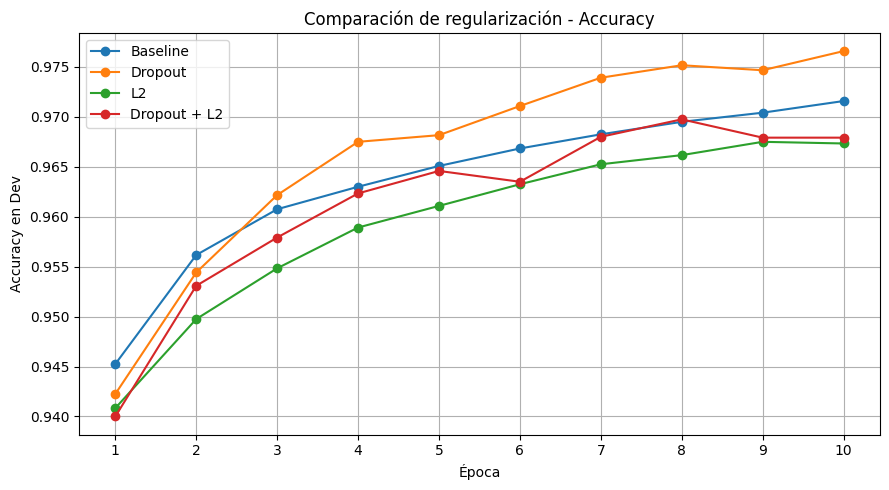

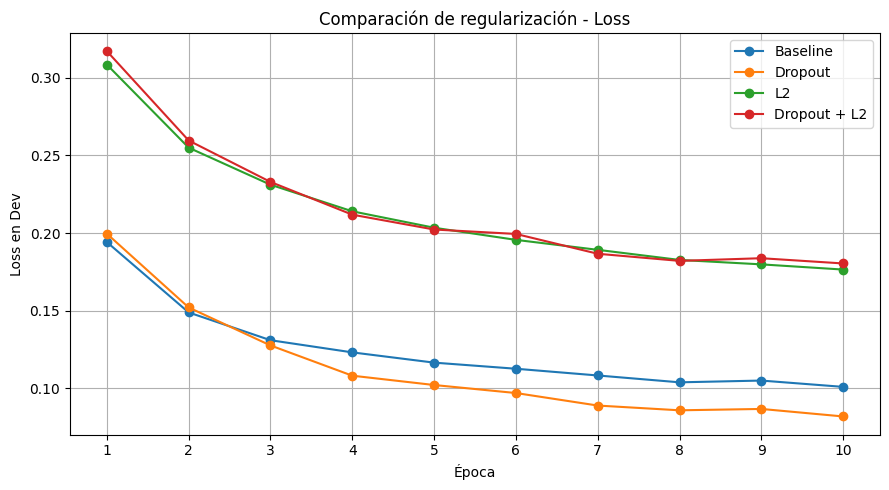

In [6]:

# Gráfica 1: Accuracy en Dev
plt.figure(figsize=(9, 5))

for nombre, historia in historias_reg.items():
    plt.plot(
        range(1, len(historia.history["val_accuracy"]) + 1),
        historia.history["val_accuracy"],
        marker="o",
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Accuracy en Dev")
plt.title("Comparación de regularización - Accuracy")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Gráfica 2: Loss en Dev
plt.figure(figsize=(9, 5))

for nombre, historia in historias_reg.items():
    plt.plot(
        range(1, len(historia.history["val_loss"]) + 1),
        historia.history["val_loss"],
        marker="o",
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Loss en Dev")
plt.title("Comparación de regularización - Loss")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [7]:

# Crear un modelo con Dropout
modelo_es = crear_modelo_regularizacion("dropout")

# Configurar Early Stopping
early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# Entrenar con Early Stopping
historia_es = modelo_es.fit(
    x_train,
    y_train,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# Evaluar el modelo con los mejores pesos restaurados
loss_dev_es, accuracy_dev_es = modelo_es.evaluate(
    x_dev, y_dev, verbose=0
)

print("\nRESULTADOS DE EARLY STOPPING")
print("Épocas ejecutadas:", len(historia_es.history["loss"]))
print("Mejor val_loss registrada:", min(historia_es.history["val_loss"]))
print("Loss en Dev del modelo restaurado:", round(loss_dev_es, 4))
print("Accuracy en Dev:", round(accuracy_dev_es, 4))


Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8854 - loss: 0.3952 - val_accuracy: 0.9427 - val_loss: 0.1998
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9430 - loss: 0.1953 - val_accuracy: 0.9576 - val_loss: 0.1472
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9551 - loss: 0.1520 - val_accuracy: 0.9625 - val_loss: 0.1286
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9619 - loss: 0.1270 - val_accuracy: 0.9663 - val_loss: 0.1120
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9667 - loss: 0.1112 - val_accuracy: 0.9703 - val_loss: 0.1021
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9711 - loss: 0.0971 - val_accuracy: 0.9725 - val_loss: 0.0947
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9726 - loss: 0.0887 - val_accuracy: 0.9737 - val_loss: 0.0918
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9753 - loss: 0.0800 - val_accuracy: 0.

EVALUACIÓN FINAL EN TEST
Accuracy: 0.9768

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.9897    0.9827    0.9862       980
           1     0.9869    0.9938    0.9903      1135
           2     0.9747    0.9719    0.9733      1032
           3     0.9724    0.9752    0.9738      1010
           4     0.9727    0.9796    0.9762       982
           5     0.9809    0.9776    0.9792       892
           6     0.9832    0.9791    0.9812       958
           7     0.9681    0.9747    0.9714      1028
           8     0.9641    0.9641    0.9641       974
           9     0.9750    0.9673    0.9711      1009

    accuracy                         0.9768     10000
   macro avg     0.9768    0.9766    0.9767     10000
weighted avg     0.9768    0.9768    0.9768     10000



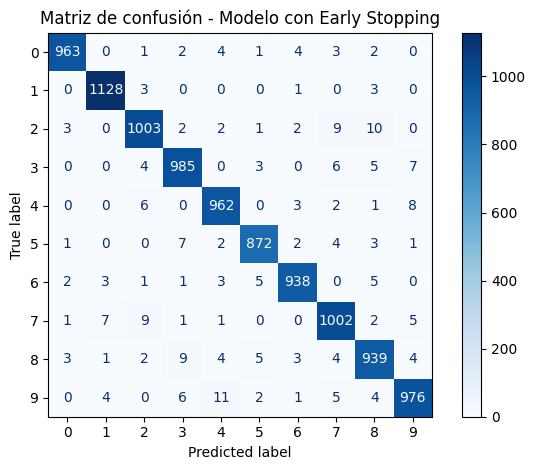

In [8]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Obtener predicciones sobre Test
probabilidades_test = modelo_es.predict(x_test, verbose=0)
y_pred_test = np.argmax(probabilidades_test, axis=1)

# Accuracy final
accuracy_test = accuracy_score(y_test, y_pred_test)

print("EVALUACIÓN FINAL EN TEST")
print("Accuracy:", round(accuracy_test, 4))

# Precision, Recall y F1-score por clase
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_test, digits=4))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Modelo con Early Stopping")
plt.tight_layout()
plt.show()


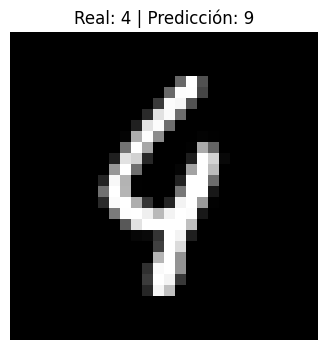

Índice de la imagen: 115
Etiqueta real: 4
Predicción: 9
Confianza de la predicción: 0.6503


In [9]:

# Encontrar imágenes clasificadas incorrectamente
errores = np.where(y_test != y_pred_test)[0]

# Seleccionar el primer error encontrado
indice = errores[0]

plt.figure(figsize=(4, 4))
plt.imshow(x_test[indice], cmap="gray")
plt.title(
    f"Real: {y_test[indice]} | "
    f"Predicción: {y_pred_test[indice]}"
)
plt.axis("off")
plt.show()

print("Índice de la imagen:", indice)
print("Etiqueta real:", y_test[indice])
print("Predicción:", y_pred_test[indice])
print(
    "Confianza de la predicción:",
    round(float(np.max(probabilidades_test[indice])), 4)
)


In [10]:

# Comparación de rendimiento en entrenamiento y validación

comparacion_bias_variance = pd.DataFrame([
    {
        "Modelo": "Baseline",
        "Train Accuracy": resultados_reg[0]["Train Accuracy"],
        "Dev Accuracy": resultados_reg[0]["Dev Accuracy"],
        "Brecha Accuracy": (
            resultados_reg[0]["Train Accuracy"]
            - resultados_reg[0]["Dev Accuracy"]
        )
    },
    {
        "Modelo": "Dropout",
        "Train Accuracy": resultados_reg[1]["Train Accuracy"],
        "Dev Accuracy": resultados_reg[1]["Dev Accuracy"],
        "Brecha Accuracy": (
            resultados_reg[1]["Train Accuracy"]
            - resultados_reg[1]["Dev Accuracy"]
        )
    }
])

display(comparacion_bias_variance.round(4))


,Modelo,Train Accuracy,Dev Accuracy,Brecha Accuracy
0,Baseline,0.9961,0.9716,0.0245
1,Dropout,0.9788,0.9766,0.0022


In [11]:

# Modelo regularizado con arquitectura 512-256
# Se conserva la función anterior para no perder los experimentos.

def crear_modelo_regularizado_guia(tipo="dropout_l2"):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten()
    ])

    if tipo in ["l2", "dropout_l2"]:
        regularizador = regularizers.l2(0.0001)
    else:
        regularizador = None

    modelo.add(layers.Dense(
        512,
        activation="relu",
        kernel_regularizer=regularizador
    ))

    if tipo in ["dropout", "dropout_l2"]:
        modelo.add(layers.Dropout(0.30))

    modelo.add(layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizador
    ))

    if tipo in ["dropout", "dropout_l2"]:
        modelo.add(layers.Dropout(0.30))

    modelo.add(layers.Dense(10, activation="softmax"))

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

print("Función de arquitectura 512-256 creada correctamente.")


Función de arquitectura 512-256 creada correctamente.


In [18]:

# ENTRENAMIENTO DEL MODELO 512-256 CON DROPOUT + L2

keras.backend.clear_session()
tf.random.set_seed(SEED)

modelo_guia = crear_modelo_regularizado_guia(
    tipo="dropout_l2"
)

early_stopping_guia = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

historia_guia = modelo_guia.fit(
    x_train_reg,
    y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping_guia],
    verbose=1
)

print("\nRESULTADOS DEL MODELO 512-256")
print("Épocas ejecutadas:", len(historia_guia.history["loss"]))
print(
    "Mejor Dev Accuracy:",
    round(max(historia_guia.history["val_accuracy"]), 4)
)
print(
    "Mejor Dev Loss:",
    round(min(historia_guia.history["val_loss"]), 4)
)


Epoch 1/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.8400 - loss: 0.6057 - val_accuracy: 0.9170 - val_loss: 0.3497
Epoch 2/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9312 - loss: 0.3089 - val_accuracy: 0.9438 - val_loss: 0.2690
Epoch 3/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9488 - loss: 0.2452 - val_accuracy: 0.9541 - val_loss: 0.2324
Epoch 4/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9597 - loss: 0.2073 - val_accuracy: 0.9571 - val_loss: 0.2203
Epoch 5/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9703 - loss: 0.1782 - val_accuracy: 0.9581 - val_loss: 0.2241
Epoch 6/30
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9725 - loss: 0.1657 - val_accuracy: 0.9569 - val_loss: 0.2301
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 4.

RESULTADOS DEL MODELO 512-256
Épocas ejecutadas: 6
Mejor Dev Accuracy: 0.9581
Mejor Dev Loss: 0.2203


In [13]:

# EVALUACIÓN DEL MODELO CON LOS MEJORES PESOS RESTAURADOS

dev_loss_final, dev_accuracy_final = modelo_guia.evaluate(
    x_dev,
    y_dev,
    verbose=0
)

mejor_epoca_loss = (
    historia_guia.history["val_loss"].index(
        min(historia_guia.history["val_loss"])
    ) + 1
)

print("RESULTADOS DEL MODELO RESTAURADO")
print("Mejor época según val_loss:", mejor_epoca_loss)
print("Dev Accuracy final:", round(dev_accuracy_final, 4))
print("Dev Loss final:", round(dev_loss_final, 4))


RESULTADOS DEL MODELO RESTAURADO
Mejor época según val_loss: 8
Dev Accuracy final: 0.9786
Dev Loss final: 0.1608


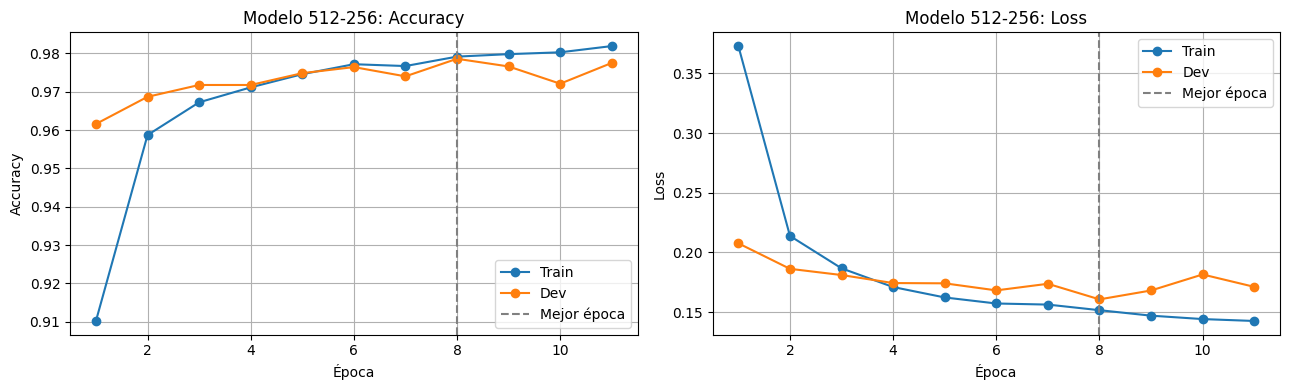

In [14]:

import matplotlib.pyplot as plt

epocas = range(1, len(historia_guia.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    epocas,
    historia_guia.history["accuracy"],
    marker="o",
    label="Train"
)
axes[0].plot(
    epocas,
    historia_guia.history["val_accuracy"],
    marker="o",
    label="Dev"
)
axes[0].axvline(
    8, linestyle="--", color="gray", label="Mejor época"
)
axes[0].set_title("Modelo 512-256: Accuracy")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epocas,
    historia_guia.history["loss"],
    marker="o",
    label="Train"
)
axes[1].plot(
    epocas,
    historia_guia.history["val_loss"],
    marker="o",
    label="Dev"
)
axes[1].axvline(
    8, linestyle="--", color="gray", label="Mejor época"
)
axes[1].set_title("Modelo 512-256: Loss")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [15]:

# EVALUACIÓN FINAL DEL MODELO 512-256 EN TEST

test_loss_guia, test_accuracy_guia = modelo_guia.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("EVALUACIÓN FINAL EN TEST - MODELO 512-256")
print("Test Accuracy:", round(test_accuracy_guia, 4))
print("Test Loss:", round(test_loss_guia, 4))


EVALUACIÓN FINAL EN TEST - MODELO 512-256
Test Accuracy: 0.981
Test Loss: 0.1485


REPORTE DE CLASIFICACIÓN - MODELO 512-256
              precision    recall  f1-score   support

           0     0.9878    0.9888    0.9883       980
           1     0.9877    0.9921    0.9899      1135
           2     0.9816    0.9845    0.9831      1032
           3     0.9879    0.9713    0.9795      1010
           4     0.9877    0.9776    0.9826       982
           5     0.9776    0.9765    0.9770       892
           6     0.9802    0.9833    0.9818       958
           7     0.9766    0.9757    0.9762      1028
           8     0.9725    0.9805    0.9765       974
           9     0.9695    0.9782    0.9739      1009

    accuracy                         0.9810     10000
   macro avg     0.9809    0.9808    0.9809     10000
weighted avg     0.9810    0.9810    0.9810     10000



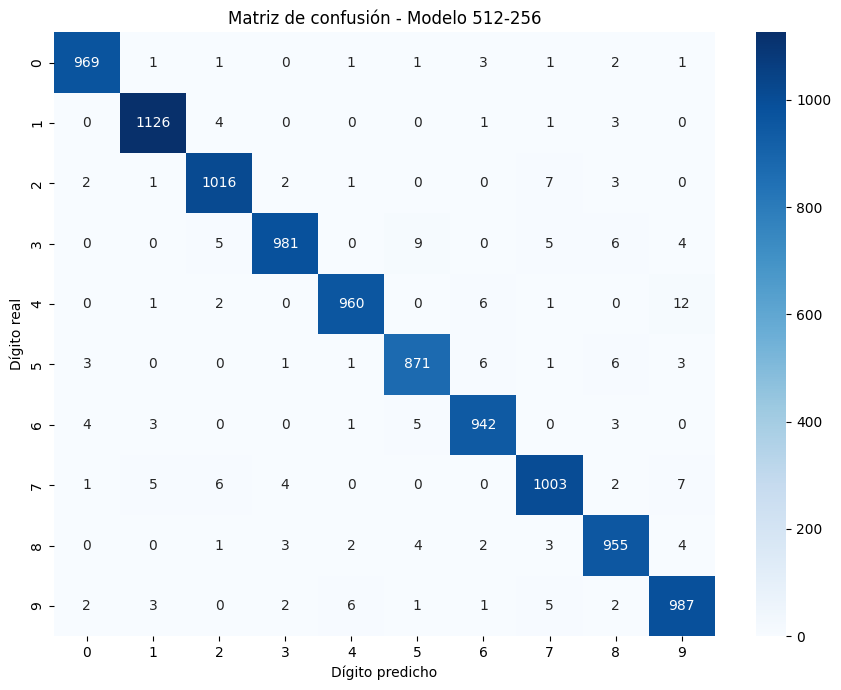

In [16]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Obtener predicciones del modelo seleccionado
probabilidades_test = modelo_guia.predict(x_test, verbose=0)
y_pred_guia = np.argmax(probabilidades_test, axis=1)

# Reporte de clasificación
print("REPORTE DE CLASIFICACIÓN - MODELO 512-256")
print(classification_report(y_test, y_pred_guia, digits=4))

# Matriz de confusión
matriz_guia = confusion_matrix(y_test, y_pred_guia)

plt.figure(figsize=(9, 7))
sns.heatmap(
    matriz_guia,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Matriz de confusión - Modelo 512-256")
plt.xlabel("Dígito predicho")
plt.ylabel("Dígito real")
plt.tight_layout()
plt.show()


In [19]:

# EVALUACIÓN DEL MODELO CON LOS PESOS RESTAURADOS

dev_loss_final, dev_accuracy_final = modelo_guia.evaluate(
    x_dev,
    y_dev,
    verbose=0
)

print("RESULTADOS DEL MODELO RESTAURADO")
print("Dev Accuracy:", round(dev_accuracy_final, 4))
print("Dev Loss:", round(dev_loss_final, 4))


RESULTADOS DEL MODELO RESTAURADO
Dev Accuracy: 0.9571
Dev Loss: 0.2203


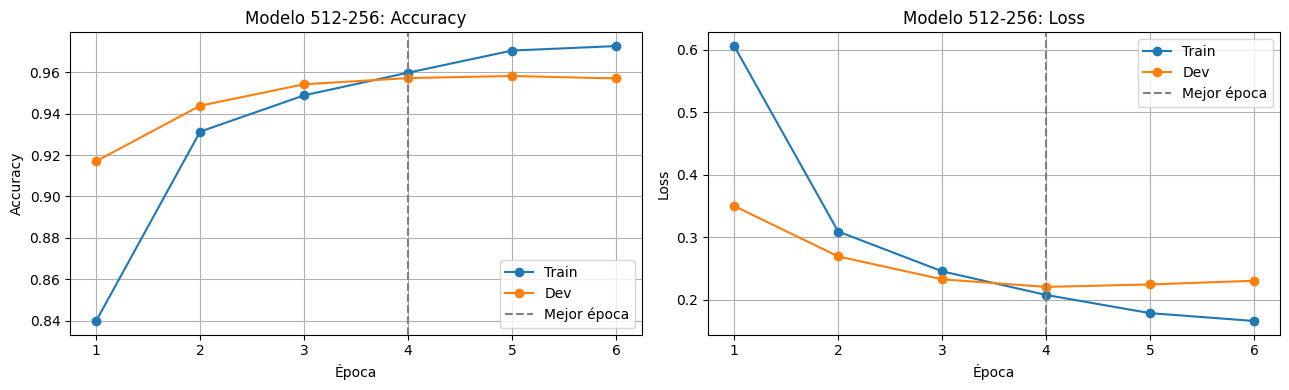

In [20]:

import matplotlib.pyplot as plt

epocas = range(1, len(historia_guia.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Accuracy
axes[0].plot(
    epocas, historia_guia.history["accuracy"],
    marker="o", label="Train"
)
axes[0].plot(
    epocas, historia_guia.history["val_accuracy"],
    marker="o", label="Dev"
)
axes[0].axvline(
    4, linestyle="--", color="gray", label="Mejor época"
)
axes[0].set_title("Modelo 512-256: Accuracy")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    epocas, historia_guia.history["loss"],
    marker="o", label="Train"
)
axes[1].plot(
    epocas, historia_guia.history["val_loss"],
    marker="o", label="Dev"
)
axes[1].axvline(
    4, linestyle="--", color="gray", label="Mejor época"
)
axes[1].set_title("Modelo 512-256: Loss")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [21]:

# EVALUACIÓN FINAL EN TEST: MODELO CON 12.000 IMÁGENES

test_loss_reg, test_accuracy_reg = modelo_guia.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("EVALUACIÓN FINAL EN TEST - MODELO 512-256")
print("Test Accuracy:", round(test_accuracy_reg, 4))
print("Test Loss:", round(test_loss_reg, 4))


EVALUACIÓN FINAL EN TEST - MODELO 512-256
Test Accuracy: 0.9586
Test Loss: 0.2147


REPORTE DE CLASIFICACIÓN - MODELO 512-256
              precision    recall  f1-score   support

           0     0.9631    0.9867    0.9748       980
           1     0.9876    0.9833    0.9854      1135
           2     0.9663    0.9438    0.9549      1032
           3     0.9582    0.9525    0.9553      1010
           4     0.9371    0.9715    0.9540       982
           5     0.9419    0.9641    0.9529       892
           6     0.9518    0.9697    0.9607       958
           7     0.9711    0.9494    0.9602      1028
           8     0.9347    0.9548    0.9446       974
           9     0.9694    0.9098    0.9387      1009

    accuracy                         0.9586     10000
   macro avg     0.9581    0.9586    0.9582     10000
weighted avg     0.9589    0.9586    0.9585     10000



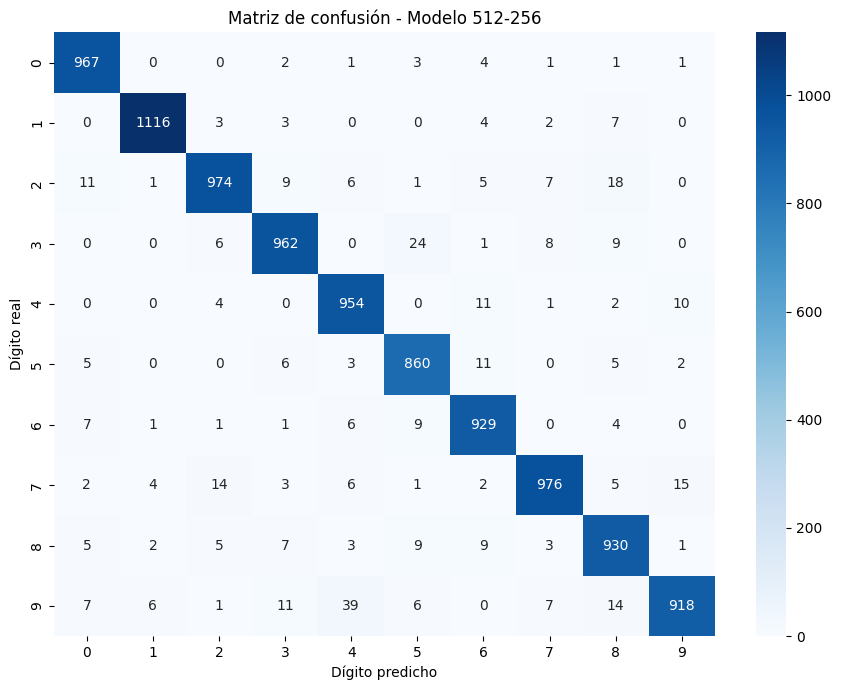

In [22]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predicciones sobre el conjunto Test
probabilidades_test_reg = modelo_guia.predict(
    x_test,
    verbose=0
)

y_pred_reg = np.argmax(probabilidades_test_reg, axis=1)

# Reporte de clasificación
print("REPORTE DE CLASIFICACIÓN - MODELO 512-256")
print(
    classification_report(
        y_test,
        y_pred_reg,
        digits=4,
        zero_division=0
    )
)

# Matriz de confusión
matriz_reg = confusion_matrix(y_test, y_pred_reg)

plt.figure(figsize=(9, 7))
sns.heatmap(
    matriz_reg,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Matriz de confusión - Modelo 512-256")
plt.xlabel("Dígito predicho")
plt.ylabel("Dígito real")
plt.tight_layout()
plt.show()


EVALUACIÓN FINAL - MODELO 512-256
Test Accuracy: 0.9586
Total de imágenes: 10000

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0     0.9631    0.9867    0.9748       980
           1     0.9876    0.9833    0.9854      1135
           2     0.9663    0.9438    0.9549      1032
           3     0.9582    0.9525    0.9553      1010
           4     0.9371    0.9715    0.9540       982
           5     0.9419    0.9641    0.9529       892
           6     0.9518    0.9697    0.9607       958
           7     0.9711    0.9494    0.9602      1028
           8     0.9347    0.9548    0.9446       974
           9     0.9694    0.9098    0.9387      1009

    accuracy                         0.9586     10000
   macro avg     0.9581    0.9586    0.9582     10000
weighted avg     0.9589    0.9586    0.9585     10000



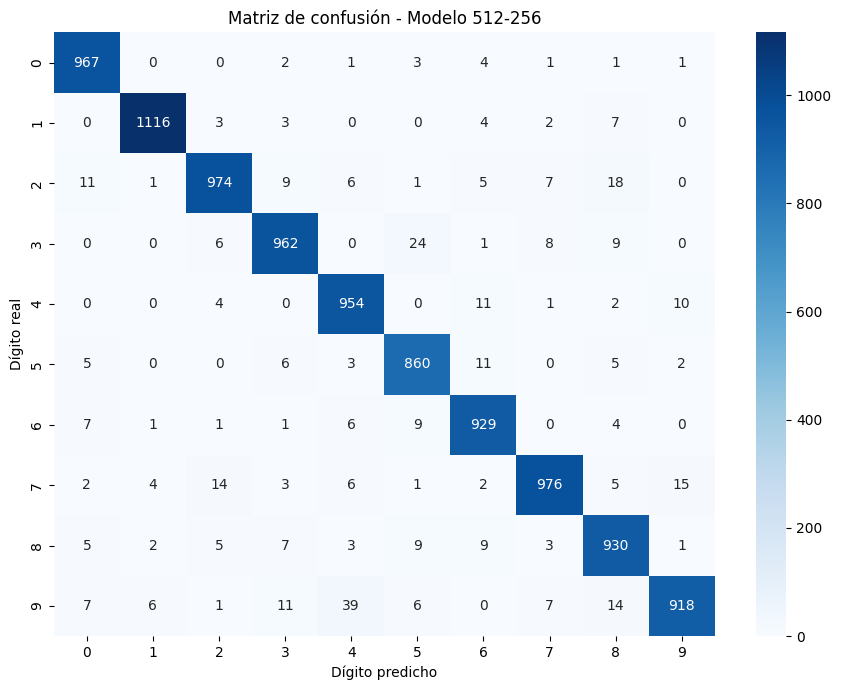

In [23]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generar predicciones nuevas con el modelo actual
probabilidades_test_reg = modelo_guia.predict(
    x_test, verbose=0
)
y_pred_reg = np.argmax(probabilidades_test_reg, axis=1)

# Calcular todas las métricas sobre las mismas predicciones
accuracy_pred = accuracy_score(y_test, y_pred_reg)
matriz_reg = confusion_matrix(y_test, y_pred_reg)

print("EVALUACIÓN FINAL - MODELO 512-256")
print("Test Accuracy:", round(accuracy_pred, 4))
print("Total de imágenes:", len(y_test))

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_test, y_pred_reg, digits=4, zero_division=0
))

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_reg, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusión - Modelo 512-256")
plt.xlabel("Dígito predicho")
plt.ylabel("Dígito real")
plt.tight_layout()
plt.show()
